<h1>Train — InceptionNet v3</h1>

Trains and evaluates InceptionNet v3 using the tuned hyperparameters from `ARCH_HYPERPARAMS["inception_v3"]`, then saves its results and weights to disk for the results notebook.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID (derived from DATASET_ROOT): chronological
Train-time augmentation: off
Classes found (3): ['Dysfunctional', 'Functional', 'Suboptimal']
Train: 947 | Val: 229 | Test: 567


## Build dataloaders + class weights for this architecture

In [2]:
cfg = ARCH_HYPERPARAMS["inception_v3"]

# The tuned batch size (cfg["batch_size"]) can be too large to fit in GPU
# memory for a deeper model like this one, even though it fit fine for
# whichever model the tuning trials actually ran on. Rather than hard-coding
# a smaller batch size (and drifting from the tuned hyperparameters), cap the
# *actual* loader batch size at MICRO_BATCH_CAP and use gradient accumulation
# in train_model to still reach the tuned effective batch size.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"InceptionNet v3: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, tuned value = {cfg['batch_size']})")

# This backbone gets its own dataloaders — its own (capped) batch size, and
# (for InceptionNet v3) its own image size.
train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

InceptionNet v3: micro batch = 16, accumulation steps = 6 (effective batch size ≈ 96, tuned value = 96)


## Define the model

In [3]:
# ---------------------------------------------------------
# Define the CNN (Transfer Learning with InceptionNet v3)
# ---------------------------------------------------------
model = models.inception_v3(weights=models.Inception_V3_Weights.IMAGENET1K_V1, aux_logits=True)

in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

# The auxiliary classifier (used only during training, see run_epoch in
# wwtw_utils.py) also needs its output layer resized to our number of classes.
in_f_aux = model.AuxLogits.fc.in_features
model.AuxLogits.fc = nn.Linear(in_f_aux, num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
# Step-based decay: LR x0.1 every Es epochs, per the Bayesian-optimized step size.
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train, then plot training curves

[InceptionNet v3] Using gradient accumulation: 6 micro-batches per optimizer step (effective batch size ≈ micro_batch x 6).


[InceptionNet v3] Epoch   1/100 | LR: 2.23e-04 | train loss 1.4207 acc 0.568 | val loss 0.7709 acc 0.729 *


[InceptionNet v3] Epoch   2/100 | LR: 2.23e-04 | train loss 0.9859 acc 0.754 | val loss 0.7270 acc 0.712 *


[InceptionNet v3] Epoch   3/100 | LR: 2.23e-04 | train loss 0.7288 acc 0.828 | val loss 0.5868 acc 0.751 *


[InceptionNet v3] Epoch   4/100 | LR: 2.23e-04 | train loss 0.6229 acc 0.804 | val loss 0.6796 acc 0.755


...

[InceptionNet v3] Epoch   9/100 | LR: 2.23e-04 | train loss 0.1656 acc 0.964 | val loss 0.9184 acc 0.760


[InceptionNet v3] Epoch  10/100 | LR: 2.23e-04 | train loss 0.1944 acc 0.948 | val loss 1.0241 acc 0.747


[InceptionNet v3] Epoch  11/100 | LR: 2.23e-04 | train loss 0.2447 acc 0.944 | val loss 0.9067 acc 0.777


[InceptionNet v3] Epoch  12/100 | LR: 2.23e-04 | train loss 0.2131 acc 0.952 | val loss 0.7655 acc 0.799


[InceptionNet v3] Epoch  13/100 | LR: 2.23e-04 | train loss 0.1375 acc 0.966 | val loss 0.7958 acc 0.790

[InceptionNet v3] No val loss improvement for 10 epochs — stopping early at epoch 13.

[InceptionNet v3] Restored best checkpoint (val loss = 0.5868)


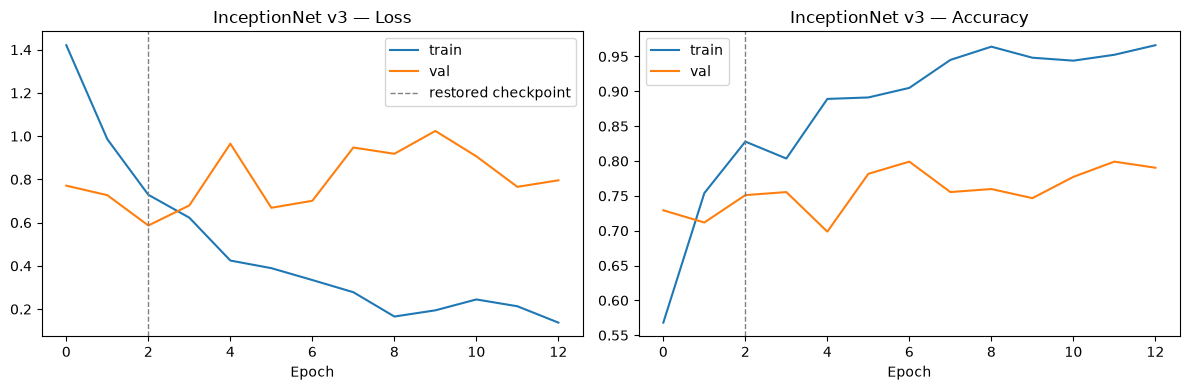

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "InceptionNet v3", is_inception=True,
    accum_steps=accum_steps,
)
plot_training_curves(history, "InceptionNet v3")

## Evaluate on the test set

[InceptionNet v3] Test accuracy: 0.795


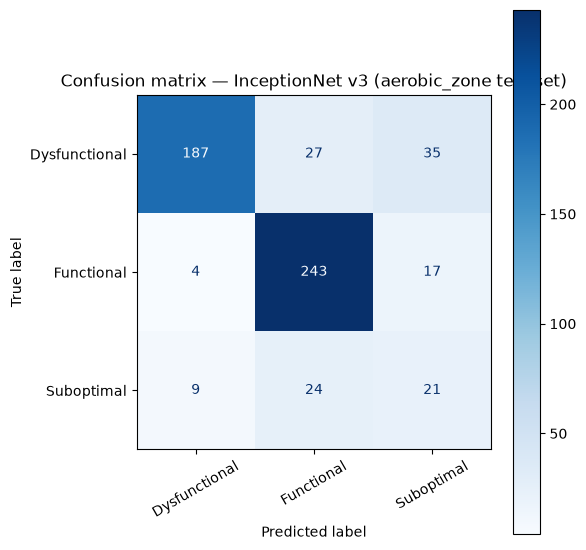

               precision    recall  f1-score   support

Dysfunctional      0.935     0.751     0.833       249
   Functional      0.827     0.920     0.871       264
   Suboptimal      0.288     0.389     0.331        54

     accuracy                          0.795       567
    macro avg      0.683     0.687     0.678       567
 weighted avg      0.823     0.795     0.803       567



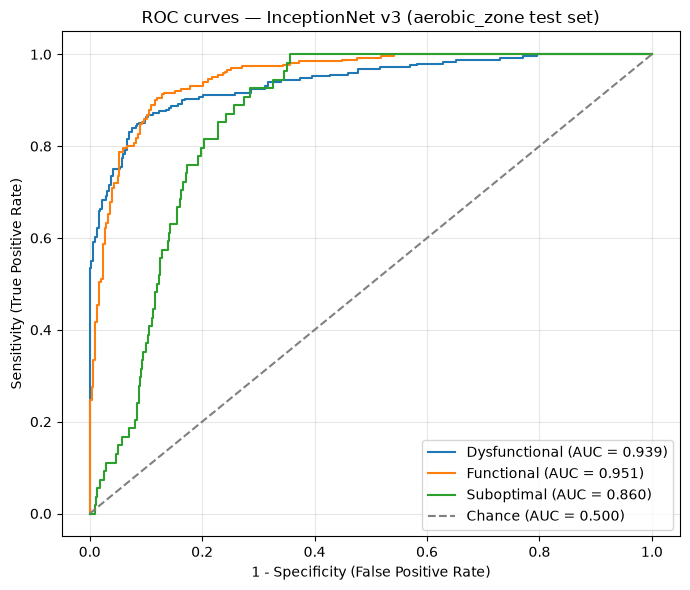

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.939
  Functional     : 0.951
  Suboptimal     : 0.860

Mean AUC (over 3/3 classes with test examples): 0.917


(np.float64(0.7954144620811288),
 {'Dysfunctional': 0.9393801621580663,
  'Functional': 0.9513451345134514,
  'Suboptimal': 0.8599379106201719})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "InceptionNet v3", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
)

## Save results + model weights to disk

In [6]:
save_result("InceptionNet v3", "inception_v3")

Saved results to ../results/aerobic_zone_noaug/results_aerobic_zone_inception_v3_chronological.pkl
Saved model weights to ../models/pad/aerobic_zone_inception_v3_cnn.pt
